<a href="https://colab.research.google.com/github/bwuu0042/Room_Occupancy_Predicition_Model/blob/main/notebooks/00_project_log.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clone the repo in Colab

In [ ]:
# from google.colab import userdata
# token = userdata.get('GITHUB_TOKEN')

# !git clone https://{token}@github.com/bwuu0042/Room_Occupancy_Predicition_Model.git
# %cd Room_Occupancy_Predicition_Model

# !git config user.email "bwuu0042@student.monash.edu"
# !git config user.name "Bill W"

Cloning into 'Room_Occupancy_Predicition_Model'...
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 5 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (5/5), done.
/content/Room_Occupancy_Predicition_Model


In [3]:
import os
from google.colab import userdata

REPO = "/content/Room_Occupancy_Predicition_Model"
if not os.path.exists(REPO):
    token = userdata.get('GITHUB_TOKEN')
    !git clone https://{token}@github.com/bwuu0042/Room_Occupancy_Predicition_Model.git /content/Room_Occupancy_Predicition_Model
%cd {REPO}

!git config user.email "bwuu0042@student.monash.edu"
!git config user.name "Bill W"

Cloning into '/content/Room_Occupancy_Predicition_Model'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 36 (delta 11), reused 11 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 24.19 KiB | 8.06 MiB/s, done.
Resolving deltas: 100% (11/11), done.
/content/Room_Occupancy_Predicition_Model


In [ ]:
!git pull

#  Project Setup

In [ ]:
# !mkdir -p src notebooks tests docs data/raw data/processed
# !touch src/__init__.py tests/__init__.py
# !touch data/raw/.gitkeep data/processed/.gitkeep

In [ ]:
# %%writefile -a .gitignore

# # Project data: large and possibly licensed, never commit
# data/raw/*
# data/processed/*
# !data/raw/.gitkeep
# !data/processed/.gitkeep
# *.parquet
# *.csv
# *.xlsx
# *.zip

Appending to .gitignore


In [ ]:
# %%writefile requirements.txt
# numpy
# pandas
# scipy
# scikit-learn
# matplotlib
# pyarrow
# openpyxl
# pytest
# pytest-html
# pdoc

Overwriting requirements.txt


In [ ]:
# !git status

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   .gitignore

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	data/
	requirements.txt
	src/
	tests/

no changes added to commit (use "git add" and/or "git commit -a")


In [ ]:
# !git add .
# !git commit -m "Add project structure, requirements and data ignore rules"
# !git push

[main b1b522b] Add project structure, requirements and data ignore rules
 6 files changed, 20 insertions(+)
 create mode 100644 data/processed/.gitkeep
 create mode 100644 data/raw/.gitkeep
 create mode 100644 requirements.txt
 create mode 100644 src/__init__.py
 create mode 100644 tests/__init__.py
Enumerating objects: 10, done.
Counting objects: 100% (10/10), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (8/8), 836 bytes | 836.00 KiB/s, done.
Total 8 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/bwuu0042/Room_Occupancy_Predicition_Model.git
   c32cc72..b1b522b  main -> main


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!ls -lh "/content/drive/MyDrive/occupancy_data"

total 88M
-rw------- 1 root root 7.1M Oct 14 06:00  5EnvSensor_MayToDec2024_180kRows.zip
-rw------- 1 root root  81M Oct 13 02:29 '5occupancySensor_MayToDec2024_9MRows (1).zip'
-rw------- 1 root root  17K Oct 13 02:28 'Sensor ID and Locations.xlsx'


In [ ]:
import zipfile
import pandas as pd

DATA = "/content/drive/MyDrive/occupancy_data/"
ENV_ZIP = DATA + "5EnvSensor_MayToDec2024_180kRows.zip"
OCC_ZIP = DATA + "5occupancySensor_MayToDec2024_9MRows (1).zip"
META_XLSX = DATA + "Sensor ID and Locations.xlsx"

for path in (ENV_ZIP, OCC_ZIP):
    with zipfile.ZipFile(path) as z:
        for info in z.infolist():
            print(info.filename, f"{info.file_size/1e6:.0f} MB uncompressed")

5EnvSensor_MayToDec2024_180kRows.csv 353 MB uncompressed
5occupancySensor_MayToDec2024_9MRows.csv 1605 MB uncompressed


# Data Inspection


In [ ]:
env_head = pd.read_csv(ENV_ZIP, nrows=5, dtype=str)
occ_head = pd.read_csv(OCC_ZIP, nrows=5, dtype=str)

print(env_head.columns.tolist())
print(occ_head.columns.tolist())
occ_head

['id', 'sensorid', 'devicetype', 'jsondata', 'status', 'processing_errors', 'createdate', 'processdate']
['id', 'deviceid', 'floorspaceid', 'occupancystatus', 'headcount', 'collecteddate', 'occupancystatuschangedate', 'previousoccupancystatus']


,id,deviceid,floorspaceid,occupancystatus,headcount,collecteddate,occupancystatuschangedate,previousoccupancystatus
0,136043,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,CurrentlyOccupied,1,2023-11-24 00:36:52+11,2023-11-24 00:36:52+11,NotOccupied
1,136048,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,RecentlyOccupied,0,2023-11-24 00:37:32+11,2023-11-24 00:37:32+11,CurrentlyOccupied
2,136050,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,CurrentlyOccupied,1,2023-11-24 00:37:32+11,2023-11-24 00:37:32+11,NotOccupied
3,136052,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,NotOccupied,0,2023-11-24 00:37:52+11,2023-11-24 00:37:52+11,RecentlyOccupied
4,136053,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,RecentlyOccupied,0,2023-11-24 00:37:52+11,2023-11-24 00:37:52+11,CurrentlyOccupied


# Sensor Metadata and room mapping

In [ ]:
env_meta = pd.read_excel(META_XLSX, sheet_name=0, dtype=str)
occ_meta = pd.read_excel(META_XLSX, sheet_name=1, dtype=str)

print(env_meta.shape, occ_meta.shape)
env_meta.head()

(78, 6) (89, 7)


,Building,Floor/Room,Area,Physical Label,Sensor,ID
0,60,1-PS01,Corridor,ES1104,Env,6012003000486
1,69,1-PS02,Breakout,ES2113,Env,6012003000882
2,60,1.40,Board Room,ES1102,Env,6012003000462
3,60,1.41,Open Office,ES1110,Env,6012003000424
4,60,1.41A,Focus Room 1,ES1101,Env,6012003000448


In [ ]:
env_meta["sensor_id"] = env_meta["ID"].str.replace(r"\.0$", "", regex=True)
env_meta[["Building", "Floor/Room", "Area", "Physical Label", "sensor_id"]].head()

,Building,Floor/Room,Area,Physical Label,sensor_id
0,60,1-PS01,Corridor,ES1104,6012003000486
1,69,1-PS02,Breakout,ES2113,6012003000882
2,60,1.40,Board Room,ES1102,6012003000462
3,60,1.41,Open Office,ES1110,6012003000424
4,60,1.41A,Focus Room 1,ES1101,6012003000448


In [ ]:
def make_key(df):
    bldg = df["Building"].str.replace(r"\.0$", "", regex=True)
    room = df["Floor/Room"].str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
    return bldg + "_" + room

env_meta["room_key"] = make_key(env_meta)
occ_meta["room_key"] = make_key(occ_meta)

common = sorted(set(env_meta["room_key"].dropna()) & set(occ_meta["room_key"].dropna()))
print(len(common), "rooms appear in both sheets")

summary = pd.DataFrame({
    "env_sensors": env_meta.groupby("room_key")["sensor_id"].nunique(),
    "occ_spaces": occ_meta.groupby("room_key")["SpaceId"].nunique(),
}).loc[common]
summary

36 rooms appear in both sheets


,env_sensors,occ_spaces
room_key,,
60_140,1.0,1.0
60_141,1.0,1.0
60_141A,1.0,1.0
60_142,1.0,1.0
60_143,1.0,1.0
60_145,1.0,1.0
60_147,1.0,1.0
60_149,1.0,1.0
60_153,1.0,1.0


# Audit the Occupancy file

###Duplicate sensor ID

In [ ]:
env_meta[env_meta["sensor_id"].duplicated(keep=False)]

,Building,Floor/Room,Area,Physical Label,Sensor,ID,sensor_id,room_key
65,69,G.52,Workshop,ES2G14,Env,6012003000691,6012003000691,69_G52
75,69,G.61,East Entrance,ES2G01,Env,6012003000691,6012003000691,69_G61


###Scan the Occupancy file in chunks

In [ ]:
from collections import Counter

space_counts = Counter()
month_counts = Counter()

for chunk in pd.read_csv(OCC_ZIP, usecols=["floorspaceid", "collecteddate"],
                         dtype=str, chunksize=500_000):
    space_counts.update(chunk["floorspaceid"].value_counts().to_dict())
    t = pd.to_datetime(chunk["collecteddate"], utc=True, errors="coerce")
    month_counts.update(t.dt.strftime("%Y-%m").value_counts().to_dict())

print(len(space_counts), "distinct floorspaceids in the data")
print(sorted(month_counts.items()))

5 distinct floorspaceids in the data
[('2023-11', 15133), ('2023-12', 49415), ('2024-01', 31958), ('2024-02', 91331), ('2024-03', 381279), ('2024-04', 356543), ('2024-05', 702321), ('2024-06', 332372), ('2024-07', 525196), ('2024-08', 761191), ('2024-09', 741583), ('2024-10', 703480), ('2024-11', 169534), ('2024-12', 188014), ('2025-01', 107629), ('2025-02', 141809), ('2025-03', 232225), ('2025-04', 212245), ('2025-05', 516511), ('2025-06', 154975), ('2025-07', 247133), ('2025-08', 361997), ('2025-09', 367217), ('2025-10', 367458), ('2025-11', 191228), ('2025-12', 144261), ('2026-01', 193526), ('2026-02', 230568), ('2026-03', 363092), ('2026-04', 210508)]


###Check the IDs against the metadata sheet

In [ ]:
meta_ids = set(occ_meta["SpaceId"].dropna())
data_ids = set(space_counts)
print("in data:", len(data_ids), "| in metadata:", len(meta_ids),
      "| in both:", len(data_ids & meta_ids))

in data: 5 | in metadata: 61 | in both: 2


#Identify the 5 spaces

###Spaces matched and what room

In [ ]:
space_table = (pd.Series(space_counts, name="events")
               .rename_axis("floorspaceid").reset_index()
               .merge(occ_meta[["SpaceId", "Building", "Floor/Room", "Area", "Note", "room_key"]],
                      left_on="floorspaceid", right_on="SpaceId", how="left")
               .sort_values("events", ascending=False))
space_table

,floorspaceid,events,SpaceId,Building,Floor/Room,Area,Note,room_key
0,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,2169461,NaN,NaN,NaN,NaN,NaN,NaN
1,941f0352-bb69-47d0-a9c5-ac29eb4f7319,1975423,NaN,NaN,NaN,NaN,NaN,NaN
2,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,1894871,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,60,G.20,NaN,NaN,60_G20
3,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,1894871,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,60,G.20,NaN,NaN,60_G20
6,3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8,1551583,NaN,NaN,NaN,NaN,NaN,NaN
4,227f1068-9e41-469f-bef0-275f27a0bdba,1500394,227f1068-9e41-469f-bef0-275f27a0bdba,60,G.25,NaN,2.4m (Keenan Lab),60_G25
5,227f1068-9e41-469f-bef0-275f27a0bdba,1500394,227f1068-9e41-469f-bef0-275f27a0bdba,60,G.25,NaN,2.4m (Keenan Lab),60_G25


###A second chunked scan with more detail per space

In [ ]:
from collections import Counter

month_parts, range_parts = [], []
headcount_counts = Counter()

for chunk in pd.read_csv(OCC_ZIP,
                         usecols=["floorspaceid", "headcount", "collecteddate"],
                         dtype=str, chunksize=500_000):
    t = pd.to_datetime(chunk["collecteddate"], utc=True, errors="coerce")
    chunk["month"] = t.dt.strftime("%Y-%m")
    chunk["t"] = t
    month_parts.append(chunk.groupby(["floorspaceid", "month"]).size().rename("events").reset_index())
    range_parts.append(chunk.groupby("floorspaceid")["t"].agg(["min", "max"]))
    headcount_counts.update(chunk.groupby(["floorspaceid", "headcount"]).size().to_dict())

per_month = (pd.concat(month_parts).groupby(["floorspaceid", "month"])["events"]
             .sum().unstack("floorspaceid").fillna(0).astype(int))
ranges = pd.concat(range_parts).groupby(level=0).agg({"min": "min", "max": "max"})

print(ranges)
print()
print(sorted(headcount_counts.items()))
per_month

                                                           min  \
floorspaceid                                                     
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7 2023-11-23 13:37:32+00:00   
227f1068-9e41-469f-bef0-275f27a0bdba 2024-03-03 04:06:30+00:00   
3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8 2024-04-30 14:00:16+00:00   
941f0352-bb69-47d0-a9c5-ac29eb4f7319 2023-11-23 13:36:52+00:00   
cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b 2024-03-03 04:06:30+00:00   

                                                           max  
floorspaceid                                                    
0f3f37f8-0335-41e0-ae87-a1d677dfc7d7 2026-04-22 13:02:18+00:00  
227f1068-9e41-469f-bef0-275f27a0bdba 2026-04-22 12:09:42+00:00  
3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8 2024-12-30 12:01:56+00:00  
941f0352-bb69-47d0-a9c5-ac29eb4f7319 2026-04-22 13:02:38+00:00  
cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b 2026-04-22 12:54:50+00:00  

[(('0f3f37f8-0335-41e0-ae87-a1d677dfc7d7', '0'), 235067), (('0f3f37f8-0335-41e0-a

floorspaceid,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,227f1068-9e41-469f-bef0-275f27a0bdba,3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8,941f0352-bb69-47d0-a9c5-ac29eb4f7319,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b
month,,,,,
2023-11,8979,0,0,6154,0
2023-12,27537,0,0,21878,0
2024-01,17502,0,0,14456,0
2024-02,52244,0,0,39087,0
2024-03,164683,53535,0,87942,75119
2024-04,130799,61659,778,99872,63435
2024-05,132038,111657,251407,107849,99370
2024-06,47758,75043,141531,40619,27421
2024-07,122078,60260,241800,66447,34611


#Extract both rooms (G.20 and G.25)

In [ ]:
TARGET_SPACES = {
    "60_G20": "cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b",
    "60_G25": "227f1068-9e41-469f-bef0-275f27a0bdba",
}

pieces = []
for chunk in pd.read_csv(OCC_ZIP, dtype=str, chunksize=500_000,
                         usecols=["id", "deviceid", "floorspaceid",
                                  "occupancystatus", "headcount", "collecteddate"]):
    keep = chunk[chunk["floorspaceid"].isin(TARGET_SPACES.values())]
    if keep.empty:
        continue
    keep = keep.assign(
        time=pd.to_datetime(keep["collecteddate"], utc=True, errors="coerce")
               .dt.tz_convert("Australia/Melbourne"),
        headcount=pd.to_numeric(keep["headcount"], errors="coerce"),
        id=pd.to_numeric(keep["id"], errors="coerce"),
    ).drop(columns="collecteddate")
    pieces.append(keep)

occ_raw = pd.concat(pieces, ignore_index=True)
for col in ["deviceid", "floorspaceid", "occupancystatus"]:
    occ_raw[col] = occ_raw[col].astype("category")

import os
os.makedirs(DATA + "processed", exist_ok=True)
occ_raw.to_parquet(DATA + "processed/occ_G20_G25_events.parquet")
print(occ_raw.shape)

(3395265, 6)


#Audit extracted data

In [ ]:
print(occ_raw.isna().sum())
print()
print(occ_raw.groupby("floorspaceid", observed=True)["deviceid"].nunique())
print()
print(occ_raw.groupby(["floorspaceid", "deviceid"], observed=True).size())
print()
print(occ_raw.duplicated(["floorspaceid", "deviceid", "time"]).sum(),
      "duplicate (space, device, time) rows")

id                 0
deviceid           0
floorspaceid       0
occupancystatus    0
headcount          0
time               0
dtype: int64

floorspaceid
227f1068-9e41-469f-bef0-275f27a0bdba    1
cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b    1
Name: deviceid, dtype: int64

floorspaceid                          deviceid                            
227f1068-9e41-469f-bef0-275f27a0bdba  56923747-b390-4f2a-8930-808429132266    1500394
cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b  56923747-b390-4f2a-8930-808429132266    1894871
dtype: int64

7 duplicate (space, device, time) rows


###Anaylse how devices in G.20 interleave

In [ ]:
g20 = occ_raw[occ_raw["floorspaceid"] == TARGET_SPACES["60_G20"]].sort_values("time")
view = g20[["time", "occupancystatus", "headcount"]].copy()
view["device"] = g20["deviceid"].astype(str).str[-4:]
view.iloc[2000:2030]

#Audit the environmental file for G.20 and G.25

In [ ]:
import json
from collections import Counter

target_env = env_meta[env_meta["room_key"].isin(["60_G20", "60_G25"])][
    ["room_key", "Area", "Physical Label", "sensor_id"]]
target_ids = set(target_env["sensor_id"])

env_counts = Counter()
stamps = []          # (sensor_id, unix_time of the row's first reading)
bad_json = 0

for chunk in pd.read_csv(ENV_ZIP, usecols=["sensorid", "jsondata"],
                         dtype=str, chunksize=20_000):
    env_counts.update(chunk["sensorid"].value_counts().to_dict())
    sub = chunk[chunk["sensorid"].isin(target_ids)]
    for sid, payload in zip(sub["sensorid"], sub["jsondata"]):
        try:
            first_time = json.loads(payload)[0]["values"][0]["time"]
        except (ValueError, KeyError, IndexError, TypeError):
            bad_json += 1
            continue
        stamps.append((sid, first_time))

print("example sensor ids in the file:", list(env_counts)[:3])
print("distinct sensor ids in env file:", len(env_counts))
print("of those found in metadata:", len(set(env_counts) & set(env_meta["sensor_id"])))
print("unparseable payloads for target sensors:", bad_json)

example sensor ids in the file: ['6012002000241', '6012002000777', '6012002000326']
distinct sensor ids in env file: 5
of those found in metadata: 1
unparseable payloads for target sensors: 0


###Summarise

In [6]:
st = pd.DataFrame(stamps, columns=["sensor_id", "unix"]).drop_duplicates()
st["time"] = pd.to_datetime(st["unix"], unit="s", utc=True).dt.tz_convert("Australia/Melbourne")
st = st.sort_values("time")

cover = st.groupby("sensor_id")["time"].agg(readings="count", first="min", last="max")
cover["median_gap_min"] = (st.groupby("sensor_id")["time"]
                           .apply(lambda s: s.diff().median().total_seconds() / 60))
target_env.merge(cover, left_on="sensor_id", right_index=True, how="left")

NameError: name 'pd' is not defined

#Finish the environmental audit

In [5]:
ids5 = set(env_counts)
stamps5, bad = [], 0
for chunk in pd.read_csv(ENV_ZIP, usecols=["sensorid", "jsondata"], dtype=str, chunksize=20_000):
    for sid, payload in zip(chunk["sensorid"], chunk["jsondata"]):
        try:
            stamps5.append((sid, json.loads(payload)[0]["values"][0]["time"]))
        except (ValueError, KeyError, IndexError, TypeError):
            bad += 1

s5 = pd.DataFrame(stamps5, columns=["sensor_id", "unix"]).drop_duplicates()
s5["time"] = pd.to_datetime(s5["unix"], unit="s", utc=True).dt.tz_convert("Australia/Melbourne")
s5 = s5.sort_values("time")

cover5 = s5.groupby("sensor_id")["time"].agg(readings="count", first="min", last="max")
cover5["median_gap_min"] = s5.groupby("sensor_id")["time"].apply(lambda s: s.diff().median().total_seconds() / 60)
cover5 = cover5.merge(env_meta[["sensor_id", "room_key", "Area", "Physical Label"]],
                      left_index=True, right_on="sensor_id", how="left")
print("unparseable:", bad)
cover5

NameError: name 'env_counts' is not defined

# Event gaps and silences in G.20 and G.25

In [4]:
occ = pd.read_parquet(DATA + "processed/occ_G20_G25_events.parquet")

# Keep one row per (space, timestamp): the highest id wins
occ = (occ.sort_values(["floorspaceid", "time", "id"])
          .drop_duplicates(["floorspaceid", "time"], keep="last"))

def silence_summary(space_id, min_hours=1):
    e = occ[occ["floorspaceid"] == space_id].sort_values("time").reset_index(drop=True)
    e["silence_h"] = e["time"].shift(-1).sub(e["time"]).dt.total_seconds() / 3600
    long = e[e["silence_h"] > min_hours]
    print(len(e), "events;", len(long), f"silences longer than {min_hours} h")
    print(e["silence_h"].describe(percentiles=[.5, .9, .99]).round(3))
    print(long.groupby("occupancystatus", observed=True)["silence_h"]
              .agg(["count", "median", "max"]).round(2))
    return long.nlargest(10, "silence_h")[["time", "occupancystatus", "headcount", "silence_h"]]

for room, sid in TARGET_SPACES.items():
    print("=====", room)
    display(silence_summary(sid))

NameError: name 'pd' is not defined

#Build the regular time series

In [8]:
import numpy as np

def build_headcount_series(events, freq="5min", max_hold="30min"):
    """Convert one space's irregular events into a regular headcount series.

    The headcount at each bin start is the last reported value. A value is held
    through any silence while the room is NotOccupied, but only for max_hold
    while the room is occupied; after that the bin is NaN (state unknown).
    Returns a Series indexed by Melbourne local time.
    """
    e = events.sort_values("time").copy()
    e["t"] = e["time"].dt.tz_convert("UTC")
    nxt = e["t"].shift(-1)
    cap = e["t"] + pd.Timedelta(max_hold)
    quiet_ok = e["occupancystatus"].astype(str).eq("NotOccupied")
    e["valid_until"] = nxt.where(quiet_ok, cap.where(cap < nxt, nxt))

    grid = pd.DataFrame({"t": pd.date_range(e["t"].min().ceil(freq),
                                            e["t"].max().floor(freq), freq=freq)})
    grid["t"] = grid["t"].astype(e["t"].dtype)
    m = pd.merge_asof(grid, e[["t", "headcount", "valid_until"]],
                      on="t", direction="backward")
    m.loc[m["t"] >= m["valid_until"], "headcount"] = np.nan

    s = m.set_index("t")["headcount"]
    s.index = s.index.tz_convert("Australia/Melbourne")
    return s

series = {room: build_headcount_series(occ[occ["floorspaceid"] == sid])
          for room, sid in TARGET_SPACES.items()}

for room, s in series.items():
    print("=====", room, "|", len(s), "bins |", f"{s.isna().mean():.2%} unknown")
    print(s.describe().round(2))

===== 60_G20 | 224745 bins | 0.17% unknown
count    224373.00
mean          0.89
std           2.39
min           0.00
25%           0.00
50%           0.00
75%           1.00
max          69.00
Name: headcount, dtype: float64
===== 60_G25 | 224736 bins | 0.58% unknown
count    223438.00
mean          0.66
std           1.45
min           0.00
25%           0.00
50%           0.00
75%           1.00
max          32.00
Name: headcount, dtype: float64


#Verify the series

###Spot check the bins against the raw events

In [9]:
rng = np.random.default_rng(42)

def spot_check(room, n=10):
    e = occ[occ["floorspaceid"] == TARGET_SPACES[room]].sort_values("time")
    s = series[room].dropna()
    rows = []
    for i in rng.choice(len(s), n, replace=False):
        ts = s.index[i]
        last = e[e["time"] <= ts].iloc[-1]
        rows.append({"bin_start": ts, "series": s.iloc[i],
                     "last_event_headcount": last["headcount"],
                     "status": last["occupancystatus"],
                     "age_min": (ts - last["time"]).total_seconds() / 60})
    out = pd.DataFrame(rows)
    out["match"] = out["series"] == out["last_event_headcount"]
    return out

for room in series:
    print(room)
    display(spot_check(room))

60_G20


,bin_start,series,last_event_headcount,status,age_min,match
0,2024-05-09 15:30:00+10:00,4.0,4,CurrentlyOccupied,0.033333,True
1,2025-10-28 15:50:00+11:00,0.0,0,NotOccupied,22.033333,True
2,2024-05-12 05:15:00+10:00,0.0,0,NotOccupied,357.200000,True
3,2025-07-27 11:20:00+10:00,1.0,1,CurrentlyOccupied,2.866667,True
4,2025-02-09 04:15:00+11:00,0.0,0,NotOccupied,458.133333,True
5,2025-02-04 14:10:00+11:00,3.0,3,CurrentlyOccupied,0.066667,True
6,2025-08-29 20:15:00+10:00,0.0,0,NotOccupied,105.700000,True
7,2024-05-16 01:25:00+10:00,0.0,0,NotOccupied,339.166667,True
8,2024-08-07 18:40:00+10:00,8.0,8,CurrentlyOccupied,0.233333,True
9,2026-01-02 17:50:00+11:00,0.0,0,NotOccupied,98.033333,True


60_G25


,bin_start,series,last_event_headcount,status,age_min,match
0,2025-11-03 02:45:00+11:00,0.0,0,NotOccupied,89.600000,True
1,2025-01-11 07:35:00+11:00,0.0,0,NotOccupied,5.433333,True
2,2024-12-17 17:05:00+11:00,1.0,1,CurrentlyOccupied,5.200000,True
3,2025-07-18 04:30:00+10:00,0.0,0,NotOccupied,202.233333,True
4,2025-12-05 07:30:00+11:00,0.0,0,NotOccupied,2.900000,True
5,2024-07-23 15:50:00+10:00,4.0,4,CurrentlyOccupied,0.000000,True
6,2025-02-17 14:35:00+11:00,1.0,1,CurrentlyOccupied,1.166667,True
7,2025-03-28 14:15:00+11:00,0.0,0,NotOccupied,4.233333,True
8,2025-05-02 16:15:00+10:00,4.0,4,CurrentlyOccupied,0.000000,True
9,2026-02-24 00:05:00+11:00,0.0,0,NotOccupied,78.700000,True


###Plot one teaching week of G.20

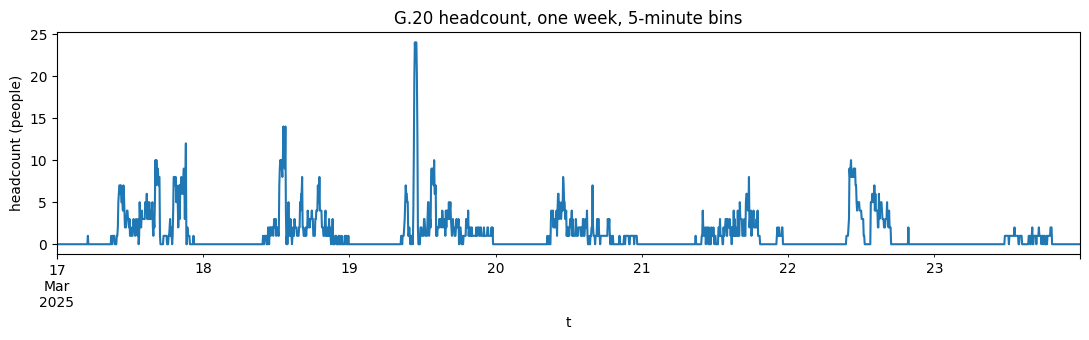

In [10]:
import matplotlib.pyplot as plt

wk = series["60_G20"]["2025-03-17":"2025-03-23"]
fig, ax = plt.subplots(figsize=(11, 3.5))
wk.plot(ax=ax)
ax.set_ylabel("headcount (people)")
ax.set_title("G.20 headcount, one week, 5-minute bins")
plt.tight_layout()
plt.show()

###Average headcount by weekday and hour (Melb Local Time)

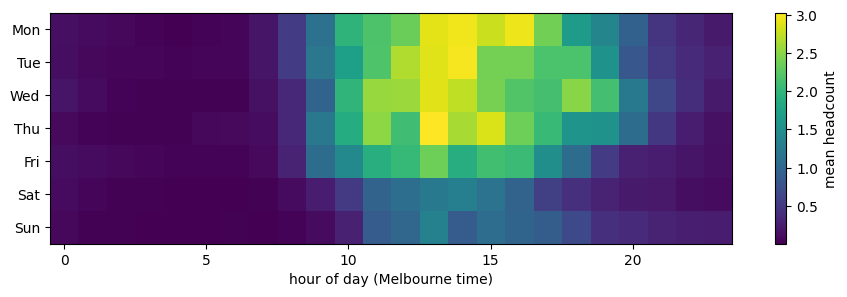

In [11]:
s = series["60_G20"].dropna()
prof = s.groupby([s.index.dayofweek, s.index.hour]).mean().unstack()
prof.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(prof.values, aspect="auto")
ax.set_yticks(range(7))
ax.set_yticklabels(prof.index)
ax.set_xlabel("hour of day (Melbourne time)")
fig.colorbar(im, label="mean headcount")
plt.show()

###Save the series to Drive

In [12]:
pd.DataFrame(series).to_parquet(DATA + "processed/headcount_5min_G20_G25.parquet")

#Gap Reconstruction Experiment (Version 1)

In [16]:
def eligible_starts(y, gap, context=1):
    """Indices i where bins i-context .. i+gap+context-1 are all known.

    i is the first hidden bin. y is a float array with NaN for unknown bins.
    """
    known = (~np.isnan(y)).astype(int)
    window = gap + 2 * context
    full = np.convolve(known, np.ones(window, dtype=int), mode="valid") == window
    return np.flatnonzero(full) + context


def carry_forward(y, i, gap):
    return np.full(gap, y[i - 1])


def linear_interp(y, i, gap):
    # straight line from the last known bin to the first known bin after the gap
    return np.linspace(y[i - 1], y[i + gap], gap + 2)[1:-1]


def per_gap_errors(y, starts, gap, methods):
    rows = []
    for i in starts:
        truth = y[i:i + gap]
        for name, fn in methods.items():
            err = fn(y, i, gap) - truth
            rows.append({"start": i, "method": name,
                         "mae": np.abs(err).mean(), "mse": (err ** 2).mean(),
                         "bias": err.mean(), "occupied": truth.max() >= 1})
    return pd.DataFrame(rows)


def summarise(res, by):
    out = res.groupby(by).agg(gaps=("mae", "size"), MAE=("mae", "mean"),
                              MSE=("mse", "mean"), bias=("bias", "mean"))
    out["RMSE"] = np.sqrt(out.pop("MSE"))
    return out.round(3)

G.20, 1hr Gap

In [15]:
y = series["60_G20"].to_numpy()          # NaN where the state is unknown
n = len(y)
test_lo, test_hi = int(0.8 * n), n        # last 20% of the timeline

gap = 12                                  # 12 bins x 5 min = 1 hour
starts = eligible_starts(y, gap)
starts = starts[(starts >= test_lo + 1) & (starts + gap + 1 <= test_hi)]

rng = np.random.default_rng(2026)         # fixed seed so results are repeatable
pick = rng.choice(starts, size=min(1000, len(starts)), replace=False)

methods = {"carry_forward": carry_forward, "linear_interp": linear_interp}
res = per_gap_errors(y, pick, gap, methods)

print(len(starts), "eligible gap positions;", len(pick), "sampled")
print("share of gaps containing occupancy:",
      round(res[res["method"] == "carry_forward"]["occupied"].mean(), 3))
display(summarise(res, ["method"]))
display(summarise(res, ["method", "occupied"]))

44674 eligible gap positions; 1000 sampled
share of gaps containing occupancy: 0.406


,gaps,MAE,bias,RMSE
method,,,,
carry_forward,1000,0.534,-0.068,1.521
linear_interp,1000,0.448,-0.032,1.200


gaps    MAE   bias   RMSE
method        occupied                           
carry_forward False      594  0.013  0.013  0.116
              True       406  1.296 -0.187  2.384
linear_interp False      594  0.016  0.016  0.123
              True       406  1.081 -0.102  1.877

#Weekly Profile Method

In [17]:
idx = series["60_G20"].index                  # Melbourne local time
slot_minutes = 30
slots = (idx.dayofweek * (24 * 60 // slot_minutes)
         + (idx.hour * 60 + idx.minute) // slot_minutes).to_numpy()

train_hi = int(0.6 * n)                       # training period: first 60%
n_slots = 7 * 24 * 60 // slot_minutes
profile = np.array([np.nanmean(y[:train_hi][slots[:train_hi] == s])
                    for s in range(n_slots)])

def make_profile_method(slots, profile):
    def weekly_profile(y, i, gap):
        return profile[slots[i:i + gap]]
    return weekly_profile

print(len(profile), "weekly slots; any missing:", np.isnan(profile).any())

336 weekly slots; any missing: False


All 3 Methods over 6 Gap lengths


In [18]:
methods = {"carry_forward": carry_forward,
           "linear_interp": linear_interp,
           "weekly_profile": make_profile_method(slots, profile)}

gap_lengths = {"15 min": 3, "30 min": 6, "1 h": 12, "2 h": 24, "4 h": 48, "8 h": 96}

all_res = []
for label, g in gap_lengths.items():
    st = eligible_starts(y, g)
    st = st[(st >= test_lo + 1) & (st + g + 1 <= test_hi)]
    pick = np.random.default_rng(2026).choice(st, size=min(1000, len(st)), replace=False)
    r = per_gap_errors(y, pick, g, methods)
    r["gap"] = label
    all_res.append(r)
all_res = pd.concat(all_res)

occ_only = all_res[all_res["occupied"]]
order = list(gap_lengths)
print("occupied gaps per length:")
print(occ_only[occ_only["method"] == "carry_forward"].groupby("gap").size().loc[order])

mae = occ_only.pivot_table(index="gap", columns="method", values="mae").loc[order]
rmse = np.sqrt(occ_only.assign(mse=occ_only["mse"])
               .pivot_table(index="gap", columns="method", values="mse")).loc[order]
print("\nMAE, occupied gaps (people)")
display(mae.round(3))
print("RMSE, occupied gaps (people)")
display(rmse.round(3))

occupied gaps per length:
gap
15 min    298
30 min    355
1 h       406
2 h       499
4 h       580
8 h       723
dtype: int64

MAE, occupied gaps (people)


method,carry_forward,linear_interp,weekly_profile
gap,,,
15 min,1.143,0.987,1.789
30 min,1.209,0.989,1.432
1 h,1.296,1.081,1.516
2 h,1.296,1.040,1.378
4 h,1.453,1.184,1.354
8 h,1.459,1.171,1.168


RMSE, occupied gaps (people)


method,carry_forward,linear_interp,weekly_profile
gap,,,
15 min,1.738,1.417,3.977
30 min,1.914,1.472,2.079
1 h,2.384,1.877,2.488
2 h,2.680,2.020,2.518
4 h,3.148,2.651,2.700
8 h,3.316,2.725,2.676


Plot Error Against Gap Length

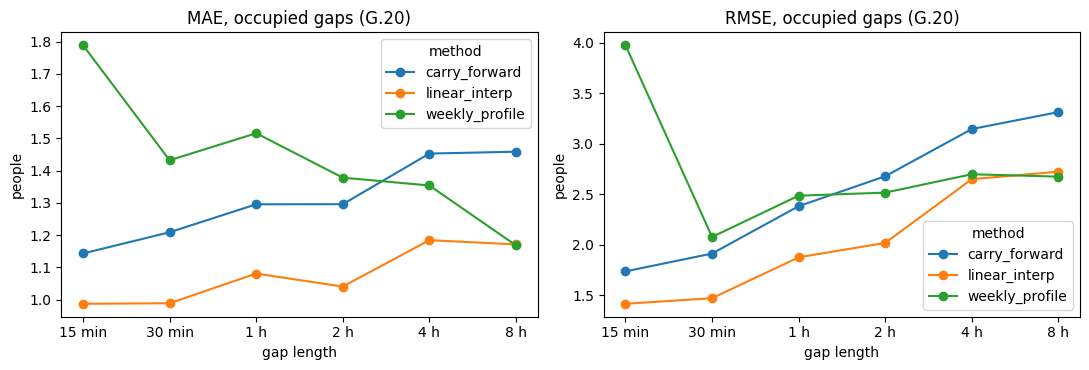

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, table, title in [(axes[0], mae, "MAE"), (axes[1], rmse, "RMSE")]:
    table.plot(ax=ax, marker="o")
    ax.set_title(f"{title}, occupied gaps (G.20)")
    ax.set_ylabel("people")
    ax.set_xlabel("gap length")
plt.tight_layout()
plt.show()

Paired Gaps, confidence intervals and the hybrid

In [21]:
def paired_starts(y, gaps, lo, hi, size, seed=2026):
    """One set of start positions used for every gap length (eligible for the longest)."""
    g_max = max(gaps)
    st = eligible_starts(y, g_max)
    st = st[(st >= lo + 1) & (st + g_max + 1 <= hi)]
    return np.random.default_rng(seed).choice(st, size=min(size, len(st)), replace=False)


def make_profile_corrected(slots, profile):
    def profile_corrected(y, i, gap):
        # interpolate the departure from the weekly profile, then add the profile back
        before = y[i - 1] - profile[slots[i - 1]]
        after = y[i + gap] - profile[slots[i + gap]]
        resid = np.linspace(before, after, gap + 2)[1:-1]
        return np.maximum(profile[slots[i:i + gap]] + resid, 0)
    return profile_corrected


def boot_ci(x, n_boot=2000, seed=1):
    rng = np.random.default_rng(seed)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

Everything on the shared gaps

In [22]:
methods = {"carry_forward": carry_forward,
           "linear_interp": linear_interp,
           "weekly_profile": make_profile_method(slots, profile),
           "profile_corrected": make_profile_corrected(slots, profile)}

starts = paired_starts(y, gap_lengths.values(), test_lo, test_hi, size=2000)
print(len(starts), "shared gap start positions")

all_res = []
for label, g in gap_lengths.items():
    r = per_gap_errors(y, starts, g, methods)
    r["gap"] = label
    all_res.append(r)
all_res = pd.concat(all_res)

order = list(gap_lengths)
occ_only = all_res[all_res["occupied"]]
print("occupied gaps per length:")
print(occ_only[occ_only["method"] == "carry_forward"].groupby("gap").size().loc[order])

print("\nMAE, occupied gaps (people)")
display(occ_only.pivot_table(index="gap", columns="method", values="mae").loc[order].round(3))
print("RMSE, occupied gaps (people)")
display(np.sqrt(occ_only.pivot_table(index="gap", columns="method", values="mse")).loc[order].round(3))
print("MAE, all gaps (people)")
display(all_res.pivot_table(index="gap", columns="method", values="mae").loc[order].round(3))

2000 shared gap start positions
occupied gaps per length:
gap
15 min     590
30 min     659
1 h        766
2 h        902
4 h       1131
8 h       1456
dtype: int64

MAE, occupied gaps (people)


method,carry_forward,linear_interp,profile_corrected,weekly_profile
gap,,,,
15 min,1.252,1.073,1.082,1.943
30 min,1.460,1.165,1.182,1.963
1 h,1.618,1.183,1.202,1.874
2 h,1.659,1.359,1.376,1.701
4 h,1.584,1.260,1.272,1.450
8 h,1.529,1.190,1.150,1.180


RMSE, occupied gaps (people)


method,carry_forward,linear_interp,profile_corrected,weekly_profile
gap,,,,
15 min,2.104,1.682,1.689,3.591
30 min,2.904,1.992,2.005,3.835
1 h,3.688,2.193,2.207,4.071
2 h,3.718,3.309,3.314,3.741
4 h,3.583,2.984,2.986,3.203
8 h,3.504,2.910,2.863,2.784


MAE, all gaps (people)


method,carry_forward,linear_interp,profile_corrected,weekly_profile
gap,,,,
15 min,0.398,0.338,0.350,0.953
30 min,0.502,0.400,0.417,0.980
1 h,0.628,0.463,0.482,0.992
2 h,0.751,0.617,0.636,0.993
4 h,0.899,0.717,0.736,0.977
8 h,1.115,0.868,0.853,0.963


Confidence Intervals on the difference from linear interpolation

In [23]:
rows = []
for label in order:
    r = occ_only[occ_only["gap"] == label]
    w = r.pivot_table(index="start", columns="method", values="mae")
    for m in w.columns:
        d = (w[m] - w["linear_interp"]).to_numpy()
        lo_, hi_ = boot_ci(d)
        rows.append({"gap": label, "method": m, "n": len(w), "MAE": w[m].mean(),
                     "diff_vs_linear": d.mean(), "ci_low": lo_, "ci_high": hi_,
                     "real_difference": (lo_ > 0) or (hi_ < 0)})
ci_table = pd.DataFrame(rows)
ci_table[ci_table["method"] != "linear_interp"].round(3)

,gap,method,n,MAE,diff_vs_linear,ci_low,ci_high,real_difference
0,15 min,carry_forward,590,1.252,0.179,0.077,0.275,True
2,15 min,profile_corrected,590,1.082,0.009,0.002,0.015,True
3,15 min,weekly_profile,590,1.943,0.870,0.669,1.111,True
4,30 min,carry_forward,659,1.460,0.295,0.212,0.389,True
6,30 min,profile_corrected,659,1.182,0.017,0.011,0.023,True
7,30 min,weekly_profile,659,1.963,0.798,0.630,1.003,True
8,1 h,carry_forward,766,1.618,0.435,0.336,0.556,True
10,1 h,profile_corrected,766,1.202,0.019,0.013,0.026,True
11,1 h,weekly_profile,766,1.874,0.691,0.540,0.856,True
12,2 h,carry_forward,902,1.659,0.300,0.200,0.394,True


Inspect the Worst error for the profile at 15 mins

In [24]:
chk = all_res[(all_res["gap"] == "15 min") & (all_res["method"] == "weekly_profile")].nlargest(5, "mse").copy()
chk["time"] = series["60_G20"].index[chk["start"].to_numpy()]
chk[["time", "mae", "mse", "occupied"]]

,time,mae,mse,occupied
7610,2026-03-12 13:50:00+11:00,30.215589,921.278916,True
2922,2026-04-13 20:00:00+10:00,27.079602,734.860399,True
2202,2026-03-12 13:15:00+11:00,26.970149,728.944506,True
3490,2026-03-12 13:10:00+11:00,25.970149,678.670874,True
7006,2026-03-31 17:50:00+11:00,18.700663,385.400479,True


###Inspect 12 Mar 2026

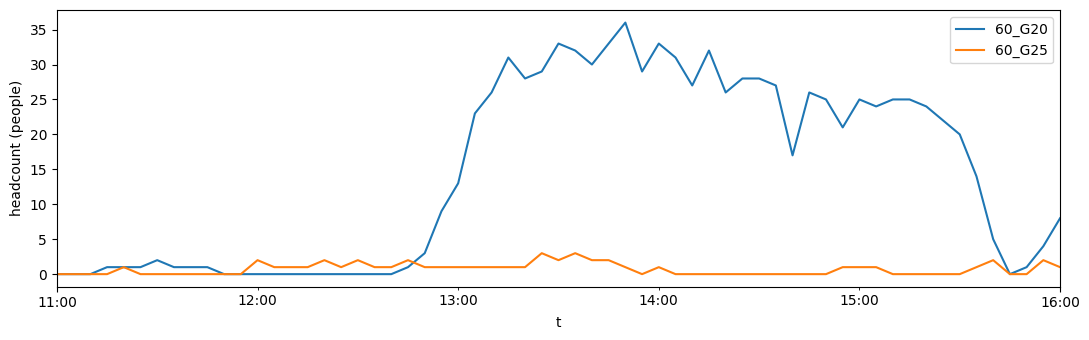

In [25]:
day = slice("2026-03-12 11:00", "2026-03-12 16:00")
fig, ax = plt.subplots(figsize=(11, 3.5))
for room in series:
    series[room][day].plot(ax=ax, label=room)
ax.set_ylabel("headcount (people)")
ax.legend()
plt.tight_layout()
plt.show()

In [26]:
both = pd.DataFrame(series).dropna()
print("5-minute correlation:")
print(both.corr().round(3))
print("\nHourly-mean correlation:")
print(both.resample("1h").mean().corr().round(3))

5-minute correlation:
        60_G20  60_G25
60_G20   1.000   0.271
60_G25   0.271   1.000

Hourly-mean correlation:
        60_G20  60_G25
60_G20   1.000   0.355
60_G25   0.355   1.000


In [27]:
day_of = series["60_G20"].index.strftime("%Y-%m-%d").to_numpy()

def cluster_boot_ci(values, groups, n_boot=2000, seed=1):
    """95% CI of the mean, resampling whole days (groups) to respect correlation."""
    g = pd.DataFrame({"v": values, "g": groups}).groupby("g")["v"].agg(["sum", "count"])
    s, c = g["sum"].to_numpy(), g["count"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    means = s[idx].sum(axis=1) / c[idx].sum(axis=1)
    return np.percentile(means, [2.5, 97.5])

def run_experiment(y, methods, gap_lengths, starts):
    out = []
    for label, g in gap_lengths.items():
        r = per_gap_errors(y, starts, g, methods)
        r["gap"] = label
        out.append(r)
    return pd.concat(out)

def compare_to_linear(res, order):
    occ_res = res[res["occupied"]]
    rows = []
    for label in order:
        w = occ_res[occ_res["gap"] == label].pivot_table(index="start", columns="method", values="mae")
        groups = day_of[w.index.to_numpy()]
        for m in w.columns:
            if m == "linear_interp":
                continue
            d = (w[m] - w["linear_interp"]).to_numpy()
            lo, hi = cluster_boot_ci(d, groups)
            rows.append({"gap": label, "method": m, "n": len(w), "MAE": w[m].mean(),
                         "diff_vs_linear": d.mean(), "ci_low": lo, "ci_high": hi,
                         "real_difference": (lo > 0) or (hi < 0)})
    return pd.DataFrame(rows)

Longer gaps (12hr and 24hr) and corrected intervals

In [28]:
gap_lengths = {"15 min": 3, "30 min": 6, "1 h": 12, "2 h": 24,
               "4 h": 48, "8 h": 96, "12 h": 144, "24 h": 288}
order = list(gap_lengths)

starts = paired_starts(y, gap_lengths.values(), test_lo, test_hi, size=2000)
print(len(starts), "shared gap start positions")

all_res = run_experiment(y, methods, gap_lengths, starts)
occ_only = all_res[all_res["occupied"]]

print("occupied gaps per length:")
print(occ_only[occ_only["method"] == "carry_forward"].groupby("gap").size().loc[order])
print("\nMAE, occupied gaps (people)")
display(occ_only.pivot_table(index="gap", columns="method", values="mae").loc[order].round(3))

ci_table = compare_to_linear(all_res, order)
display(ci_table.round(3))

2000 shared gap start positions
occupied gaps per length:
gap
15 min     653
30 min     721
1 h        818
2 h        966
4 h       1178
8 h       1473
12 h      1674
24 h      1863
dtype: int64

MAE, occupied gaps (people)


method,carry_forward,linear_interp,profile_corrected,weekly_profile
gap,,,,
15 min,1.324,1.081,1.092,1.813
30 min,1.416,1.086,1.098,1.732
1 h,1.479,1.145,1.166,1.637
2 h,1.503,1.228,1.251,1.509
4 h,1.536,1.249,1.263,1.379
8 h,1.525,1.245,1.199,1.152
12 h,1.543,1.247,1.128,1.036
24 h,1.423,1.352,1.091,0.958


,gap,method,n,MAE,diff_vs_linear,ci_low,ci_high,real_difference
0,15 min,carry_forward,653,1.324,0.243,0.163,0.334,True
1,15 min,profile_corrected,653,1.092,0.011,0.006,0.017,True
2,15 min,weekly_profile,653,1.813,0.732,0.517,0.971,True
3,30 min,carry_forward,721,1.416,0.330,0.234,0.446,True
4,30 min,profile_corrected,721,1.098,0.012,0.005,0.019,True
5,30 min,weekly_profile,721,1.732,0.646,0.480,0.835,True
6,1 h,carry_forward,818,1.479,0.333,0.247,0.429,True
7,1 h,profile_corrected,818,1.166,0.020,0.014,0.026,True
8,1 h,weekly_profile,818,1.637,0.492,0.384,0.617,True
9,2 h,carry_forward,966,1.503,0.275,0.199,0.362,True


Does G25 carry info beyond the weekly rhythm?

In [29]:
both = pd.DataFrame(series).dropna()
tr = int(0.6 * len(both))
sl = (both.index.dayofweek * 48 + (both.index.hour * 60 + both.index.minute) // 30).to_numpy()

dev = both.copy()
for room in both.columns:
    v = both[room].to_numpy()
    prof_r = np.array([v[:tr][sl[:tr] == k].mean() for k in range(336)])
    dev[room] = v - prof_r[sl]          # deviation from the room's weekly profile

val = dev.iloc[tr:int(0.8 * len(dev))]
print("5-minute correlation of deviations (validation period):")
print(val.corr().round(3))
print("\nHourly-mean correlation of deviations:")
print(val.resample("1h").mean().corr().round(3))

5-minute correlation of deviations (validation period):
        60_G20  60_G25
60_G20   1.000   0.012
60_G25   0.012   1.000

Hourly-mean correlation of deviations:
        60_G20  60_G25
60_G20   1.000   0.015
60_G25   0.015   1.000


Fading correction method

In [31]:
def make_decay_method(slots, profile, tau_bins):
    """Profile plus interpolated boundary anomaly, fading with distance from the nearest known bin."""
    def decay(y, i, gap):
        t = np.arange(i, i + gap)
        before = y[i - 1] - profile[slots[i - 1]]
        after = y[i + gap] - profile[slots[i + gap]]
        resid = np.linspace(before, after, gap + 2)[1:-1]
        nearest = np.minimum(t - (i - 1), (i + gap) - t)   # bins to the closest known value
        return np.maximum(profile[slots[t]] + resid * np.exp(-nearest / tau_bins), 0)
    return decay

In [32]:
val_starts = paired_starts(y, gap_lengths.values(), train_hi, test_lo, size=1500, seed=7)
print(len(val_starts), "validation gap start positions")

taus = [6, 12, 24, 48, 96, 192]            # 30 min to 16 h, in 5-minute bins
rows = []
for tau in taus:
    r = run_experiment(y, {"decay": make_decay_method(slots, profile, tau)},
                       gap_lengths, val_starts)
    r = r[r["occupied"]]
    rows.append({"tau_bins": tau, "tau_hours": round(tau * 5 / 60, 1),
                 "mean_MAE": r.groupby("gap")["mae"].mean().mean()})
tune = pd.DataFrame(rows)
display(tune.round(3))

1500 validation gap start positions


,tau_bins,tau_hours,mean_MAE
0,6,0.5,0.946
1,12,1.0,0.904
2,24,2.0,0.886
3,48,4.0,0.887
4,96,8.0,0.897
5,192,16.0,0.908


chosen tau (bins): 24


method,carry_forward,decay_profile,linear_interp,profile_corrected,weekly_profile
gap,,,,,
15 min,1.324,1.086,1.081,1.092,1.813
30 min,1.416,1.088,1.086,1.098,1.732
1 h,1.479,1.150,1.145,1.166,1.637
2 h,1.503,1.210,1.228,1.251,1.509
4 h,1.536,1.189,1.249,1.263,1.379
8 h,1.525,1.076,1.245,1.199,1.152
12 h,1.543,0.987,1.247,1.128,1.036
24 h,1.423,0.920,1.352,1.091,0.958


,gap,method,n,MAE,diff_vs_linear,ci_low,ci_high,real_difference
1,15 min,decay_profile,653,1.086,0.006,-0.006,0.018,False
5,30 min,decay_profile,721,1.088,0.002,-0.011,0.016,False
9,1 h,decay_profile,818,1.150,0.005,-0.012,0.024,False
13,2 h,decay_profile,966,1.210,-0.018,-0.045,0.009,False
17,4 h,decay_profile,1178,1.189,-0.060,-0.108,-0.011,True
21,8 h,decay_profile,1473,1.076,-0.169,-0.249,-0.083,True
25,12 h,decay_profile,1674,0.987,-0.260,-0.347,-0.170,True
29,24 h,decay_profile,1863,0.920,-0.432,-0.548,-0.323,True


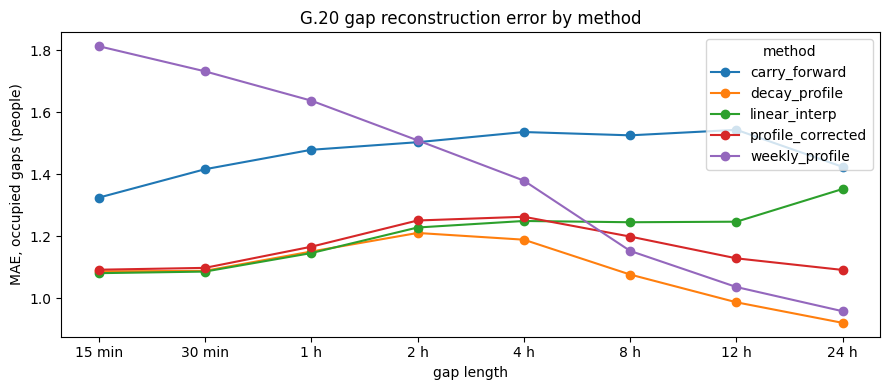

In [33]:
best_tau = int(tune.loc[tune["mean_MAE"].idxmin(), "tau_bins"])
print("chosen tau (bins):", best_tau)

methods["decay_profile"] = make_decay_method(slots, profile, best_tau)
all_res = run_experiment(y, methods, gap_lengths, starts)
occ_only = all_res[all_res["occupied"]]

mae_tab = occ_only.pivot_table(index="gap", columns="method", values="mae").loc[order]
display(mae_tab.round(3))
display(compare_to_linear(all_res, order).query("method == 'decay_profile'").round(3))

ax = mae_tab.plot(marker="o", figsize=(9, 4))
ax.set_ylabel("MAE, occupied gaps (people)")
ax.set_xlabel("gap length")
ax.set_title("G.20 gap reconstruction error by method")
plt.tight_layout()
plt.show()

# Regression Method

In [42]:
def gap_features(y, i, gap, slots, profile):
    """Feature matrix for every bin of the gap starting at index i (own-room data only)."""
    t = np.arange(i, i + gap)
    prof_t = profile[slots[t]]
    before = y[i - 1] - profile[slots[i - 1]]
    after = y[i + gap] - profile[slots[i + gap]]
    d_before = t - (i - 1)
    d_after = (i + gap) - t
    lin_resid = np.linspace(before, after, gap + 2)[1:-1]
    return np.column_stack([prof_t,
                            np.full(gap, before), np.full(gap, after),
                            d_before, d_after, np.minimum(d_before, d_after),
                            np.full(gap, gap), lin_resid])

In [43]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

X_tr, Y_tr = make_training_set(y, slots, profile, 1, train_hi, 4000, seed=11)
X_va, Y_va = make_training_set(y, slots, profile, train_hi, test_lo, 1500, seed=12)
print("training rows:", X_tr.shape, " validation rows:", X_va.shape)

# reference points on the same validation rows (anomaly errors, in people)
print("profile only (anomaly = 0):        ", round(np.abs(Y_va).mean(), 4))
print("profile-corrected interpolation:   ", round(np.abs(Y_va - X_va[:, 7]).mean(), 4))

lin = LinearRegression().fit(X_tr, Y_tr)
print("linear regression:                  ", round(mean_absolute_error(Y_va, lin.predict(X_va)), 4))

for depth in [4, 8, 12, 16, None]:
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=50, random_state=0).fit(X_tr, Y_tr)
    print(f"decision tree, max_depth={depth}:", round(mean_absolute_error(Y_va, tree.predict(X_va)), 4))

training rows: (239264, 8)  validation rows: (94013, 8)
profile only (anomaly = 0):         0.8702
profile-corrected interpolation:    0.9517
linear regression:                   0.8614
decision tree, max_depth=4: 0.821
decision tree, max_depth=8: 0.8299
decision tree, max_depth=12: 0.871
decision tree, max_depth=16: 0.8875
decision tree, max_depth=None: 0.9271


validation rows, MAE / RMSE (people)
profile only:       0.8702 2.1756
decay profile:      0.7759 2.1018


,depth,train_MAE,validation_MAE,validation_RMSE
0,1,1.0019,0.8558,2.1708
1,2,1.0088,0.9030,2.1805
2,3,0.9414,0.8637,2.1626
3,4,0.8874,0.8210,2.1496
4,5,0.8579,0.8004,2.1441
5,6,0.8379,0.8050,2.1717
6,7,0.8181,0.8164,2.2162
7,8,0.7979,0.8299,2.2536
8,9,0.7736,0.8412,2.3038
9,10,0.7623,0.8545,2.3233


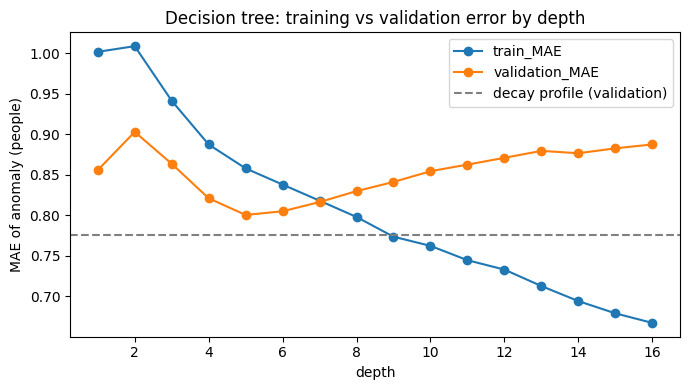

In [44]:
def mae(a, b):
    return float(np.abs(a - b).mean())

def rmse(a, b):
    return float(np.sqrt(((a - b) ** 2).mean()))

# decay_profile rule rebuilt from the features: interpolated anomaly x exp(-nearest / tau), tau = 24 bins
decay_va = X_va[:, 7] * np.exp(-X_va[:, 5] / 24)
zero_va = np.zeros_like(Y_va)

print("validation rows, MAE / RMSE (people)")
print("profile only:      ", round(mae(Y_va, zero_va), 4), round(rmse(Y_va, zero_va), 4))
print("decay profile:     ", round(mae(Y_va, decay_va), 4), round(rmse(Y_va, decay_va), 4))

depths = list(range(1, 17))
rows = []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, min_samples_leaf=50, random_state=0).fit(X_tr, Y_tr)
    rows.append({"depth": d,
                 "train_MAE": mae(Y_tr, t.predict(X_tr)),
                 "validation_MAE": mae(Y_va, t.predict(X_va)),
                 "validation_RMSE": rmse(Y_va, t.predict(X_va))})
curve = pd.DataFrame(rows)
display(curve.round(4))

ax = curve.plot(x="depth", y=["train_MAE", "validation_MAE"], marker="o", figsize=(7, 4))
ax.axhline(mae(Y_va, decay_va), color="gray", linestyle="--", label="decay profile (validation)")
ax.set_ylabel("MAE of anomaly (people)")
ax.set_title("Decision tree: training vs validation error by depth")
ax.legend()
plt.tight_layout()
plt.show()

### SVR and Neural Network

In [4]:
import time
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR

rng = np.random.default_rng(5)
tr_sub = rng.choice(len(X_tr), 8000, replace=False)
va_sub = rng.choice(len(X_va), 20000, replace=False)   # smaller validation sample: SVR prediction is slow
Xv, Yv = X_va[va_sub], Y_va[va_sub]

decay_v = Xv[:, 7] * np.exp(-Xv[:, 5] / 24)
print("same rows, MAE / RMSE:")
print("  profile only:", round(mae(Yv, 0 * Yv), 4), round(rmse(Yv, 0 * Yv), 4))
print("  decay profile:", round(mae(Yv, decay_v), 4), round(rmse(Yv, decay_v), 4))

results = []
for C in [0.1, 1, 10]:
    t0 = time.perf_counter()
    m = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=C, epsilon=0.1, gamma="scale"))
    m.fit(X_tr[tr_sub], Y_tr[tr_sub])
    fit_s = time.perf_counter() - t0
    p = m.predict(Xv)
    results.append({"model": f"SVR C={C}", "MAE": mae(Yv, p), "RMSE": rmse(Yv, p), "fit_seconds": fit_s})
display(pd.DataFrame(results).round(4))

same rows, MAE / RMSE:
  profile only: 0.8651 2.1611
  decay profile: 0.7638 2.0568


,model,MAE,RMSE,fit_seconds
0,SVR C=0.1,0.6694,2.1508,2.4086
1,SVR C=1,0.6828,2.1448,1.9109
2,SVR C=10,0.7035,2.1657,3.2015


In [5]:
from sklearn.neural_network import MLPRegressor

for hidden, alpha in [((16,), 1e-3), ((32, 32), 1e-3), ((32, 32), 1e-1)]:
    t0 = time.perf_counter()
    m = make_pipeline(StandardScaler(),
                      MLPRegressor(hidden_layer_sizes=hidden, alpha=alpha,
                                   max_iter=60, random_state=0))
    m.fit(X_tr, Y_tr)
    fit_s = time.perf_counter() - t0
    p = m.predict(Xv)
    results.append({"model": f"MLP {hidden} alpha={alpha}", "MAE": mae(Yv, p),
                    "RMSE": rmse(Yv, p), "fit_seconds": fit_s})

res_tab = pd.DataFrame(results)
display(res_tab.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,MAE,RMSE,fit_seconds
0,SVR C=0.1,0.6694,2.1508,2.4086
1,SVR C=1,0.6828,2.1448,1.9109
2,SVR C=10,0.7035,2.1657,3.2015
3,"MLP (16,) alpha=0.001",0.8105,2.0998,28.7662
4,"MLP (32, 32) alpha=0.001",0.8520,2.2037,51.9886
5,"MLP (32, 32) alpha=0.1",0.8260,2.2274,50.8248


Find out why SVR wins on MAE

In [6]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

preds = {"profile only": np.zeros(len(Yv)), "decay profile": decay_v}
for C in [0.01, 0.03, 0.1]:
    m = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=C, epsilon=0.1, gamma="scale"))
    m.fit(X_tr[tr_sub], Y_tr[tr_sub])
    preds[f"SVR C={C}"] = m.predict(Xv)

prof = Xv[:, 0]
truth = Yv + prof                      # actual headcount
busy = truth >= 1
print("share of rows that are busy:", round(busy.mean(), 3))

def block(h, t):
    return mae(t, h), rmse(t, h), float((h - t).mean())

rows = []
for name, p in preds.items():
    h = np.maximum(prof + p, 0)        # headcount can't be negative
    a = block(h, truth)
    b = block(h[busy], truth[busy])
    e = block(h[~busy], truth[~busy])
    rows.append({"method": name,
                 "MAE_all": a[0], "RMSE_all": a[1], "bias_all": a[2],
                 "MAE_busy": b[0], "RMSE_busy": b[1], "bias_busy": b[2],
                 "MAE_empty": e[0], "bias_empty": e[2]})
display(pd.DataFrame(rows).round(3))

share of rows that are busy: 0.308


,method,MAE_all,RMSE_all,bias_all,MAE_busy,RMSE_busy,bias_busy,MAE_empty,bias_empty
0,profile only,0.865,2.161,0.182,1.589,3.644,-0.628,0.543,0.543
1,decay profile,0.755,2.056,0.092,1.508,3.497,-0.646,0.420,0.420
2,SVR C=0.01,0.667,2.147,-0.263,1.656,3.797,-1.362,0.226,0.226
3,SVR C=0.03,0.657,2.149,-0.294,1.693,3.809,-1.395,0.197,0.197
4,SVR C=0.1,0.658,2.150,-0.306,1.729,3.814,-1.401,0.181,0.181


In [7]:
from sklearn.tree import DecisionTreeRegressor

sub = np.random.default_rng(3).choice(len(X_tr), 60000, replace=False)
for d in [3, 5, 8]:
    t0 = time.perf_counter()
    tr_abs = DecisionTreeRegressor(criterion="absolute_error", max_depth=d,
                                   min_samples_leaf=50, random_state=0).fit(X_tr[sub], Y_tr[sub])
    p = tr_abs.predict(Xv)
    print(f"tree (absolute error) depth {d}: MAE {mae(Yv, p):.4f}  RMSE {rmse(Yv, p):.4f}  "
          f"fit {time.perf_counter() - t0:.0f}s")

tree (absolute error) depth 3: MAE 0.6946  RMSE 2.1589  fit 79s
tree (absolute error) depth 5: MAE 0.6692  RMSE 2.1313  fit 89s
tree (absolute error) depth 8: MAE 0.6714  RMSE 2.1920  fit 96s


###Final Test on Fresh Gaps

In [7]:
sub = np.random.default_rng(3).choice(len(X_tr), 60000, replace=False)
frozen = {
    "tree_sq_d5": DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=0).fit(X_tr, Y_tr),
    "tree_abs_d5": DecisionTreeRegressor(criterion="absolute_error", max_depth=5,
                                         min_samples_leaf=50, random_state=0).fit(X_tr[sub], Y_tr[sub]),
    "svr_c003": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=0.03, epsilon=0.1, gamma="scale"))
                .fit(X_tr[tr_sub], Y_tr[tr_sub]),
}
print("fitted:", list(frozen))

fitted: ['tree_sq_d5', 'tree_abs_d5', 'svr_c003']


In [8]:
def eligible_starts(y, gap, context=1):
    known = (~np.isnan(y)).astype(int)
    window = gap + 2 * context
    full = np.convolve(known, np.ones(window, dtype=int), mode="valid") == window
    return np.flatnonzero(full) + context

gap_lengths = {"15 min": 3, "30 min": 6, "1 h": 12, "2 h": 24,
               "4 h": 48, "8 h": 96, "12 h": 144, "24 h": 288}
order = list(gap_lengths)

st = eligible_starts(y, max(gap_lengths.values()))
st = st[(st >= test_lo + 1) & (st + 288 + 1 <= n)]
starts = np.random.default_rng(9001).choice(st, size=min(2000, len(st)), replace=False)
print(len(st), "eligible;", len(starts), "used")

def predict_all(i, g):
    X = gap_features(y, i, g, slots, profile)
    prof_g = X[:, 0]
    out = {
        "carry_forward": np.full(g, y[i - 1]),
        "linear_interp": np.linspace(y[i - 1], y[i + g], g + 2)[1:-1],
        "weekly_profile": prof_g,
        "decay_profile": np.maximum(prof_g + X[:, 7] * np.exp(-X[:, 5] / 24), 0),
    }
    for name, m in frozen.items():
        out[name] = np.maximum(prof_g + m.predict(X), 0)
    return out

rows = []
for label, g in gap_lengths.items():
    for i in starts:
        truth = y[i:i + g]
        for name, h in predict_all(i, g).items():
            e = h - truth
            rows.append({"gap": label, "start": i, "method": name,
                         "mae": np.abs(e).mean(), "mse": (e ** 2).mean(),
                         "bias": e.mean(), "busy": truth.max() >= 1})
test_res = pd.DataFrame(rows)
print(len(test_res), "rows")

40588 eligible; 2000 used
112000 rows


In [9]:
busy = test_res[test_res["busy"]]
print("busy gaps per length:")
print(busy[busy["method"] == "decay_profile"].groupby("gap").size().loc[order])

print("\nMAE, busy gaps")
display(busy.pivot_table(index="gap", columns="method", values="mae").loc[order].round(3))
print("RMSE, busy gaps")
display(np.sqrt(busy.pivot_table(index="gap", columns="method", values="mse")).loc[order].round(3))
print("MAE, all gaps")
display(test_res.pivot_table(index="gap", columns="method", values="mae").loc[order].round(3))

busy gaps per length:
gap
15 min     622
30 min     688
1 h        785
2 h        926
4 h       1172
8 h       1472
12 h      1676
24 h      1851
dtype: int64

MAE, busy gaps


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,1.260,1.029,1.034,1.520,1.346,1.262,1.827
30 min,1.453,1.135,1.120,1.541,1.393,1.355,1.835
1 h,1.563,1.235,1.230,1.506,1.411,1.428,1.773
2 h,1.626,1.358,1.386,1.432,1.417,1.429,1.661
4 h,1.583,1.227,1.258,1.226,1.218,1.278,1.423
8 h,1.516,1.055,1.177,0.970,0.979,1.084,1.157
12 h,1.525,0.990,1.248,0.882,0.893,1.021,1.048
24 h,1.426,0.931,1.401,0.837,0.829,1.037,0.968


RMSE, busy gaps


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,2.203,1.659,1.677,3.420,2.574,2.286,3.602
30 min,2.851,1.897,1.896,3.589,2.869,2.605,3.752
1 h,3.297,2.283,2.254,3.634,3.049,2.885,3.772
2 h,3.474,2.946,3.110,3.438,3.170,3.040,3.513
4 h,3.582,2.802,2.869,3.113,2.951,2.877,3.135
8 h,3.401,2.414,2.722,2.556,2.539,2.543,2.543
12 h,3.435,2.331,2.842,2.476,2.460,2.473,2.427
24 h,3.338,2.262,3.186,2.338,2.359,2.739,2.305


MAE, all gaps


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,0.408,0.363,0.341,0.550,0.474,0.559,0.947
30 min,0.511,0.431,0.396,0.593,0.524,0.614,0.973
1 h,0.622,0.535,0.491,0.643,0.594,0.692,0.998
2 h,0.758,0.690,0.647,0.700,0.686,0.771,1.014
4 h,0.930,0.788,0.740,0.744,0.737,0.832,1.013
8 h,1.117,0.839,0.870,0.732,0.737,0.853,0.967
12 h,1.279,0.885,1.048,0.756,0.762,0.901,0.963
24 h,1.320,0.902,1.297,0.798,0.781,0.991,0.946


In [10]:
def cluster_boot_ci(values, groups, n_boot=2000, seed=1):
    g = pd.DataFrame({"v": values, "g": groups}).groupby("g")["v"].agg(["sum", "count"])
    s, c = g["sum"].to_numpy(), g["count"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    return np.percentile(s[idx].sum(axis=1) / c[idx].sum(axis=1), [2.5, 97.5])

day_of = series["60_G20"].index.strftime("%Y-%m-%d").to_numpy()

rows = []
for label in order:
    w = busy[busy["gap"] == label].pivot_table(index="start", columns="method", values="mae")
    groups = day_of[w.index.to_numpy()]
    for m in w.columns:
        if m == "decay_profile":
            continue
        d = (w[m] - w["decay_profile"]).to_numpy()
        lo, hi = cluster_boot_ci(d, groups)
        rows.append({"gap": label, "method": m, "n": len(w), "diff_vs_decay": d.mean(),
                     "ci_low": lo, "ci_high": hi, "real": (lo > 0) or (hi < 0)})
ci = pd.DataFrame(rows)
display(ci.round(3))

,gap,method,n,diff_vs_decay,ci_low,ci_high,real
0,15 min,carry_forward,622,0.231,0.143,0.322,True
1,15 min,linear_interp,622,0.005,-0.005,0.016,False
2,15 min,svr_c003,622,0.491,0.234,0.832,True
3,15 min,tree_abs_d5,622,0.317,0.152,0.549,True
4,15 min,tree_sq_d5,622,0.233,0.117,0.401,True
5,15 min,weekly_profile,622,0.798,0.523,1.149,True
6,30 min,carry_forward,688,0.318,0.229,0.411,True
7,30 min,linear_interp,688,-0.015,-0.034,0.001,False
8,30 min,svr_c003,688,0.406,0.195,0.690,True
9,30 min,tree_abs_d5,688,0.258,0.115,0.451,True


###Save Results and Check Bias

In [11]:
test_res.to_parquet(DATA + "processed/test_results_seed9001.parquet")

order = ["15 min", "30 min", "1 h", "2 h", "4 h", "8 h", "12 h", "24 h"]
busy = test_res[test_res["busy"]]
print("Mean bias on busy gaps (people; negative = under-predicts)")
display(busy.pivot_table(index="gap", columns="method", values="bias").loc[order].round(2))

Mean bias on busy gaps (people; negative = under-predicts)


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,-0.05,-0.03,0.02,-1.10,-0.81,-0.06,-0.85
30 min,-0.12,-0.06,-0.01,-1.03,-0.77,-0.09,-0.74
1 h,-0.18,-0.13,-0.06,-0.97,-0.74,-0.12,-0.64
2 h,-0.18,-0.14,-0.06,-0.82,-0.63,-0.18,-0.46
4 h,-0.14,-0.18,-0.16,-0.67,-0.56,-0.16,-0.25
8 h,-0.03,-0.04,-0.07,-0.51,-0.41,-0.03,-0.05
12 h,-0.02,0.01,0.00,-0.49,-0.38,0.02,-0.01
24 h,-0.00,0.03,0.03,-0.34,-0.34,0.12,0.03


### Replicate in G.25 with no retuning

In [12]:
def eligible_starts(y, gap, context=1):
    known = (~np.isnan(y)).astype(int)
    window = gap + 2 * context
    full = np.convolve(known, np.ones(window, dtype=int), mode="valid") == window
    return np.flatnonzero(full) + context

def run_room(room, n_test=1000, seed_test=9001):
    yr = series[room].to_numpy()
    nr = len(yr)
    tr_hi, te_lo = int(0.6 * nr), int(0.8 * nr)
    ix = series[room].index
    sl = (ix.dayofweek * 48 + (ix.hour * 60 + ix.minute) // 30).to_numpy()
    prof = np.array([np.nanmean(yr[:tr_hi][sl[:tr_hi] == s]) for s in range(336)])

    # training on the first 60% only, same recipe and seeds as G.20
    Xt, Yt = make_training_set(yr, sl, prof, 1, tr_hi, 4000, seed=11)
    sv = np.random.default_rng(5).choice(len(Xt), min(8000, len(Xt)), replace=False)
    sb = np.random.default_rng(3).choice(len(Xt), min(60000, len(Xt)), replace=False)
    models = {
        "tree_sq_d5": DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=0).fit(Xt, Yt),
        "tree_abs_d5": DecisionTreeRegressor(criterion="absolute_error", max_depth=5,
                                             min_samples_leaf=50, random_state=0).fit(Xt[sb], Yt[sb]),
        "svr_c003": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=0.03, epsilon=0.1,
                                                        gamma="scale")).fit(Xt[sv], Yt[sv]),
    }

    # fresh test gaps from the last 20%
    st = eligible_starts(yr, 288)
    st = st[(st >= te_lo + 1) & (st + 289 <= nr)]
    starts = np.random.default_rng(seed_test).choice(st, size=min(n_test, len(st)), replace=False)
    print(room, ":", len(st), "eligible;", len(starts), "used")

    rows = []
    for label, g in gap_lengths.items():
        X = np.vstack([gap_features(yr, i, g, sl, prof) for i in starts])
        pg = X[:, 0].reshape(len(starts), g)
        truth = np.array([yr[i:i + g] for i in starts])
        preds = {
            "carry_forward": np.repeat(yr[starts - 1][:, None], g, axis=1),
            "linear_interp": np.array([np.linspace(yr[i - 1], yr[i + g], g + 2)[1:-1] for i in starts]),
            "weekly_profile": pg,
            "decay_profile": np.maximum(pg + (X[:, 7] * np.exp(-X[:, 5] / 24)).reshape(pg.shape), 0),
        }
        for name, m in models.items():
            preds[name] = np.maximum(pg + m.predict(X).reshape(pg.shape), 0)
        busy_flag = truth.max(axis=1) >= 1
        for name, h in preds.items():
            e = h - truth
            rows.append(pd.DataFrame({"gap": label, "start": starts, "method": name,
                                      "mae": np.abs(e).mean(1), "mse": (e ** 2).mean(1),
                                      "bias": e.mean(1), "busy": busy_flag}))
    return pd.concat(rows, ignore_index=True)

gap_lengths = {"15 min": 3, "30 min": 6, "1 h": 12, "2 h": 24,
               "4 h": 48, "8 h": 96, "12 h": 144, "24 h": 288}
order = list(gap_lengths)

t0 = time.perf_counter()
res25 = run_room("60_G25")
print(f"took {time.perf_counter() - t0:.0f} s")
res25.to_parquet(DATA + "processed/test_results_G25_seed9001.parquet")

b = res25[res25["busy"]]
print("busy gaps per length:")
print(b[b["method"] == "decay_profile"].groupby("gap").size().loc[order])
print("\nMAE, busy gaps");  display(b.pivot_table(index="gap", columns="method", values="mae").loc[order].round(3))
print("RMSE, busy gaps"); display(np.sqrt(b.pivot_table(index="gap", columns="method", values="mse")).loc[order].round(3))
print("Bias, busy gaps"); display(b.pivot_table(index="gap", columns="method", values="bias").loc[order].round(2))

60_G25 : 40147 eligible; 1000 used
took 260 s
busy gaps per length:
gap
15 min     446
30 min     578
1 h        711
2 h        815
4 h        904
8 h        967
12 h       992
24 h      1000
dtype: int64

MAE, busy gaps


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,0.549,0.513,0.501,0.618,0.660,0.590,0.842
30 min,0.505,0.489,0.466,0.571,0.575,0.578,0.853
1 h,0.483,0.488,0.447,0.541,0.518,0.577,0.852
2 h,0.477,0.502,0.435,0.505,0.484,0.561,0.825
4 h,0.474,0.552,0.434,0.475,0.451,0.573,0.807
8 h,0.496,0.612,0.443,0.457,0.439,0.588,0.770
12 h,0.503,0.641,0.458,0.448,0.433,0.606,0.750
24 h,0.520,0.678,0.499,0.522,0.437,0.922,0.737


RMSE, busy gaps


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,0.888,0.752,0.768,0.792,0.883,0.750,1.054
30 min,0.867,0.725,0.732,0.779,0.833,0.753,1.098
1 h,0.854,0.730,0.733,0.762,0.794,0.764,1.110
2 h,0.856,0.751,0.748,0.750,0.790,0.766,1.088
4 h,0.857,0.789,0.738,0.719,0.750,0.773,1.071
8 h,0.895,0.874,0.752,0.720,0.749,0.818,1.035
12 h,0.901,0.913,0.781,0.715,0.748,0.858,1.013
24 h,0.918,0.946,0.851,0.798,0.761,1.406,1.003


Bias, busy gaps


method,carry_forward,decay_profile,linear_interp,svr_c003,tree_abs_d5,tree_sq_d5,weekly_profile
gap,,,,,,,
15 min,-0.12,-0.09,-0.11,-0.27,-0.45,-0.08,0.12
30 min,-0.06,-0.01,-0.04,-0.14,-0.33,0.04,0.28
1 h,-0.04,0.04,-0.02,-0.08,-0.24,0.11,0.38
2 h,-0.04,0.08,-0.03,-0.08,-0.22,0.12,0.41
4 h,-0.02,0.18,-0.00,-0.06,-0.16,0.18,0.44
8 h,-0.01,0.25,-0.02,-0.07,-0.13,0.21,0.42
12 h,-0.01,0.30,-0.02,-0.07,-0.10,0.24,0.42
24 h,-0.00,0.35,0.00,0.08,-0.08,0.66,0.41


### CHeck Profile Drift (No model changes)

In [13]:
rows = []
for room in series:
    yr = series[room].to_numpy()
    nr = len(yr)
    tr, te = int(0.6 * nr), int(0.8 * nr)
    ix = series[room].index
    sl = (ix.dayofweek * 48 + (ix.hour * 60 + ix.minute) // 30).to_numpy()
    prof = np.array([np.nanmean(yr[:tr][sl[:tr] == s]) for s in range(336)])
    for name, seg in {"train": slice(0, tr), "validation": slice(tr, te), "test": slice(te, nr)}.items():
        actual = yr[seg]
        rows.append({"room": room, "period": name,
                     "start": ix[seg][0].date(), "end": ix[seg][-1].date(),
                     "mean_headcount": np.nanmean(actual),
                     "share_busy": np.nanmean(actual[~np.isnan(actual)] >= 1),
                     "profile_mean_for_period": prof[sl[seg]].mean(),
                     "profile_minus_actual": prof[sl[seg]].mean() - np.nanmean(actual)})
display(pd.DataFrame(rows).round(3))

,room,period,start,end,mean_headcount,share_busy,profile_mean_for_period,profile_minus_actual
0,60_G20,train,2024-03-03,2025-06-14,0.948,0.325,0.947,-0.000
1,60_G20,validation,2025-06-14,2025-11-17,0.749,0.306,0.945,0.196
2,60_G20,test,2025-11-17,2026-04-22,0.853,0.273,0.949,0.096
3,60_G25,train,2024-03-03,2025-06-14,0.763,0.350,0.762,-0.002
4,60_G25,validation,2025-06-14,2025-11-17,0.611,0.364,0.759,0.149
5,60_G25,test,2025-11-17,2026-04-22,0.377,0.301,0.763,0.386


In [14]:
day25 = series["60_G25"].index.strftime("%Y-%m-%d").to_numpy()
b = res25[res25["busy"]]
rows = []
for label in order:
    w = b[b["gap"] == label].pivot_table(index="start", columns="method", values="mae")
    groups = day25[w.index.to_numpy()]
    for m in w.columns:
        if m == "linear_interp":
            continue
        d = (w[m] - w["linear_interp"]).to_numpy()
        lo, hi = cluster_boot_ci(d, groups)
        rows.append({"gap": label, "method": m, "n": len(w), "diff_vs_linear": d.mean(),
                     "ci_low": lo, "ci_high": hi, "real": (lo > 0) or (hi < 0)})
display(pd.DataFrame(rows).round(3))

,gap,method,n,diff_vs_linear,ci_low,ci_high,real
0,15 min,carry_forward,446,0.048,0.015,0.081,True
1,15 min,decay_profile,446,0.012,0.007,0.017,True
2,15 min,svr_c003,446,0.116,0.079,0.155,True
3,15 min,tree_abs_d5,446,0.159,0.109,0.210,True
4,15 min,tree_sq_d5,446,0.088,0.061,0.116,True
5,15 min,weekly_profile,446,0.340,0.275,0.407,True
6,30 min,carry_forward,578,0.039,0.013,0.067,True
7,30 min,decay_profile,578,0.023,0.017,0.030,True
8,30 min,svr_c003,578,0.105,0.076,0.135,True
9,30 min,tree_abs_d5,578,0.109,0.073,0.149,True
